### Task 5: Pivot Translation (+15%)
A pivot language, sometimes also called a bridge language, is an artificial or natural language used as
an intermediary language for translation between many different languages – to translate between
any pair of languages A and B, one translates A to the pivot language P, then from P to B.

For this task, you should develop a neural machine translation model for translating Dutch to Swedish,
using English as the pivot language.

Idea: both corpora (nl-en and sv-en) are aligned to English, and a large part of the english
sentences is identical in both. So we join the two corpora over the english side to get
nl-en-sv triples. We fine-tune one pre-trained MarianMT model per hop (nl->en and en->sv)
on the same split and chain them at test time. The swedish side of the test triples gives
us a real reference to evaluate the pivot translation.

In [1]:
# !pip install torch transformers datasets accelerate sentencepiece sacrebleu

In [ ]:
import codecs

with codecs.open("../data/europarl-v7.nl-en.en", 'r', encoding='utf-8') as f:
    nlen_en = f.read().splitlines()
with codecs.open("../data/europarl-v7.nl-en.nl", 'r', encoding='utf-8') as f:
    nlen_nl = f.read().splitlines()

with codecs.open("../data/sv-en/europarl-v7.sv-en.en", 'r', encoding='utf-8') as f:
    sven_en = f.read().splitlines()
with codecs.open("../data/sv-en/europarl-v7.sv-en.sv", 'r', encoding='utf-8') as f:
    sven_sv = f.read().splitlines()

print(f"nl-en pairs: {len(nlen_en)}")
print(f"sv-en pairs: {len(sven_en)}")

nl-en pairs: 1997775
sv-en pairs: 1862234


In [3]:
# join the two corpora over the identical english sentences -> nl-en-sv triples
en_to_nl = {}
for e, n in zip(nlen_en, nlen_nl):
    if e.strip() != '' and n.strip() != '' and e not in en_to_nl:
        en_to_nl[e] = n

triples = []
seen = set()
for e, s in zip(sven_en, sven_sv):
    if e in en_to_nl and s.strip() != '' and e not in seen:
        triples.append((en_to_nl[e], e, s))
        seen.add(e)

print(f"nl-en-sv triples: {len(triples)}")

nl-en-sv triples: 1649331


In [ ]:
import random

# sample 10%
random.seed(14)
triples = random.sample(triples, len(triples) // 10)
print(f"sampled triples: {len(triples)}")

sampled triples: 164933


In [ ]:
import re
import pandas as pd

# lowercase and remove punctuation
def clean(s):
    s = s.lower()
    s = re.sub(r"[^\w\s]", '', s)
    return ' '.join(s.split())

triples = [(clean(n), clean(e), clean(s)) for n, e, s in triples]
triples = [t for t in triples if all(t)]

# keep only short sentences so training stays feasible
MAX_LEN = 15
triples = [t for t in triples if all(len(x.split()) <= MAX_LEN for x in t)]

df = pd.DataFrame(triples, columns=['nl', 'en', 'sv'])
print(f"triples after cleaning + length filter: {len(df)}")

df.sample(5, random_state=14)

triples after cleaning + length filter: 35829


,nl,en,sv
19649,is het niet veeleer zo dat we voor meer bureau...,is it not rather the case that we are creating...,är det inte snarare så att vi ökar byråkratin ...
32808,toch zal ik afronden met twee bemoedigende con...,i would however like to conclude on two encour...,jag vill dock avsluta med två positiva punkter
2924,de vergadering wordt om 2000 uur onderbroken e...,the sitting was suspended at 8 pm and resumed ...,sammanträdet avbröts kl 2000 och återupptogs k...
3463,ik wil er nog eens duidelijk op wijzen dat dit...,i believe we must insist on their being able t...,jag menar att vi måste insistera på att de ska...
31298,er zijn grotere problemen dan dit zoals de hog...,there are bigger issues than this such as high...,det finns större frågor än denna exempelvis ar...


In [ ]:
# train / validation / test split (20% test)
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df, test_size=0.2, random_state=14)
train_df, val_df = train_test_split(train_df, test_size=0.125, random_state=14)

print(f"train: {len(train_df)}")
print(f"val: {len(val_df)}")
print(f"test: {len(test_df)}")

train: 25080
val: 3583
test: 7166


In [7]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, set_seed

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(device)

set_seed(14)

# two pre-trained marian translation models, one per hop
tokenizer_a = AutoTokenizer.from_pretrained('Helsinki-NLP/opus-mt-nl-en')
model_a = AutoModelForSeq2SeqLM.from_pretrained('Helsinki-NLP/opus-mt-nl-en').to(device)

tokenizer_b = AutoTokenizer.from_pretrained('Helsinki-NLP/opus-mt-en-sv')
model_b = AutoModelForSeq2SeqLM.from_pretrained('Helsinki-NLP/opus-mt-en-sv').to(device)

/Users/bensc/Documents/MI-Master/FS_1/NLP/Projects/project_2/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


mps


/Users/bensc/Documents/MI-Master/FS_1/NLP/Projects/project_2/.venv/lib/python3.11/site-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")
Loading weights: 100%|██████████| 258/258 [00:00<00:00, 39360.22it/s]


In [8]:
# greedy batch translation
def translate(model, tokenizer, sentences, batch_size=32):
    model.eval()
    out = []
    for i in range(0, len(sentences), batch_size):
        batch = tokenizer(sentences[i:i + batch_size], return_tensors='pt',
                          padding=True, truncation=True, max_length=32).to(model.device)
        with torch.no_grad():
            gen = model.generate(**batch, num_beams=1, max_new_tokens=40)
        out += tokenizer.batch_decode(gen, skip_special_tokens=True)
    return out

# quick check before fine-tuning
print(translate(model_a, tokenizer_a, [test_df.iloc[0]['nl']]))
print(test_df.iloc[0]['en'])

[transformers] Both `max_new_tokens` (=40) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


['Is it not more that we create more bureaucracy and complex procedures?']
is it not rather the case that we are creating more bureaucracy and complicated procedures


In [9]:
# zero-shot pivot with the pre-trained models, before any fine-tuning
# 2000 test sentences are enough for evaluation and keep the runtime ok
test_eval = test_df.head(2000)

zs_en = translate(model_a, tokenizer_a, list(test_eval['nl']))
zs_sv_pivot = translate(model_b, tokenizer_b, zs_en)

[transformers] Both `max_new_tokens` (=40) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

In [10]:
# tokenization for fine-tuning
from datasets import Dataset
from transformers import DataCollatorForSeq2Seq

max_length = 32

def make_datasets(src_col, trg_col, tokenizer):
    def tokenize(batch):
        return tokenizer(batch[src_col], text_target=batch[trg_col],
                         truncation=True, max_length=max_length)
    cols = [src_col, trg_col]
    train = Dataset.from_pandas(train_df[cols], preserve_index=False).map(tokenize, batched=True)
    val = Dataset.from_pandas(val_df[cols], preserve_index=False).map(tokenize, batched=True)
    return train, val

train_a, val_a = make_datasets('nl', 'en', tokenizer_a)
train_b, val_b = make_datasets('en', 'sv', tokenizer_b)

collator_a = DataCollatorForSeq2Seq(tokenizer_a, model=model_a)
collator_b = DataCollatorForSeq2Seq(tokenizer_b, model=model_b)

Map: 100%|██████████| 3583/3583 [00:00<00:00, 14779.47 examples/s]


In [11]:
# training arguments, same setup for both hops
from transformers import TrainingArguments, Trainer

def make_trainer(model, train_data, val_data, collator, tokenizer, output_dir):
    args = TrainingArguments(
        output_dir=output_dir,
        learning_rate=2e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,
        num_train_epochs=2,
        weight_decay=0.01,
        eval_strategy='epoch',
        logging_strategy='epoch',
        report_to='none',
        load_best_model_at_end=True,
        save_strategy='epoch',
        save_total_limit=1)
    return Trainer(
        model=model,
        args=args,
        train_dataset=train_data,
        eval_dataset=val_data,
        data_collator=collator,
        processing_class=tokenizer)

In [12]:
# fine-tune model a: dutch -> english
trainer_a = make_trainer(model_a, train_a, val_a, collator_a, tokenizer_a, './marian-nl-en')
result_a = trainer_a.train()

print(result_a.metrics)

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
/Users/bensc/Documents/MI-Master/FS_1/NLP/Projects/project_2/.venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss
1,1.480816,1.291740
2,1.297264,1.279983


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.62it/s]
/Users/bensc/Documents/MI-Master/FS_1/NLP/Projects/project_2/.venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.05it/s]
[transformers] There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.encoder.embed_positions.weight', 'model.decoder.embed_tokens.weight', 'model.decoder.embed_positions.weight', 'lm_head.weight'].


{'train_runtime': 1063.281, 'train_samples_per_second': 47.175, 'train_steps_per_second': 2.949, 'total_flos': 248536455708672.0, 'train_loss': 1.3890398375842037, 'epoch': 2.0}


In [13]:
# fine-tune model b: english -> swedish
trainer_b = make_trainer(model_b, train_b, val_b, collator_b, tokenizer_b, './marian-en-sv')
result_b = trainer_b.train()

print(result_b.metrics)

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
/Users/bensc/Documents/MI-Master/FS_1/NLP/Projects/project_2/.venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss
1,1.330670,1.179208
2,1.158344,1.170885


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.47it/s]
/Users/bensc/Documents/MI-Master/FS_1/NLP/Projects/project_2/.venv/lib/python3.11/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.40it/s]
[transformers] There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.encoder.embed_positions.weight', 'model.decoder.embed_tokens.weight', 'model.decoder.embed_positions.weight', 'lm_head.weight'].


{'train_runtime': 997.2957, 'train_samples_per_second': 50.296, 'train_steps_per_second': 3.145, 'total_flos': 236563976945664.0, 'train_loss': 1.244506952713947, 'epoch': 2.0}


In [14]:
# pivot translation on the test set with the fine-tuned models: nl -> en -> sv
hyp_en = translate(model_a, tokenizer_a, list(test_eval['nl']))
hyp_sv_pivot = translate(model_b, tokenizer_b, hyp_en)

# for comparison: en -> sv with the clean english input instead of the translated one
hyp_sv_clean = translate(model_b, tokenizer_b, list(test_eval['en']))

ref_en = list(test_eval['en'])
ref_sv = list(test_eval['sv'])

[transformers] Both `max_new_tokens` (=40) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

In [15]:
import sacrebleu

# two metrics: bleu and chrf
def scores(hyps, refs):
    bleu = sacrebleu.corpus_bleu(hyps, [refs]).score
    chrf = sacrebleu.corpus_chrf(hyps, [refs]).score
    return bleu, chrf

results = {
    'nl->sv pivot zero-shot': scores(zs_sv_pivot, ref_sv),
    'nl->en fine-tuned (model a)': scores(hyp_en, ref_en),
    'en->sv clean input fine-tuned (model b)': scores(hyp_sv_clean, ref_sv),
    'nl->sv pivot fine-tuned': scores(hyp_sv_pivot, ref_sv),
}

for name, (bleu, chrf) in results.items():
    print(f"{name}: BLEU {bleu:.2f}, chrF {chrf:.2f}")

nl->sv pivot zero-shot: BLEU 17.62, chrF 50.95
nl->en fine-tuned (model a): BLEU 35.45, chrF 60.84
en->sv clean input fine-tuned (model b): BLEU 38.03, chrF 64.15
nl->sv pivot fine-tuned: BLEU 25.65, chrF 55.37


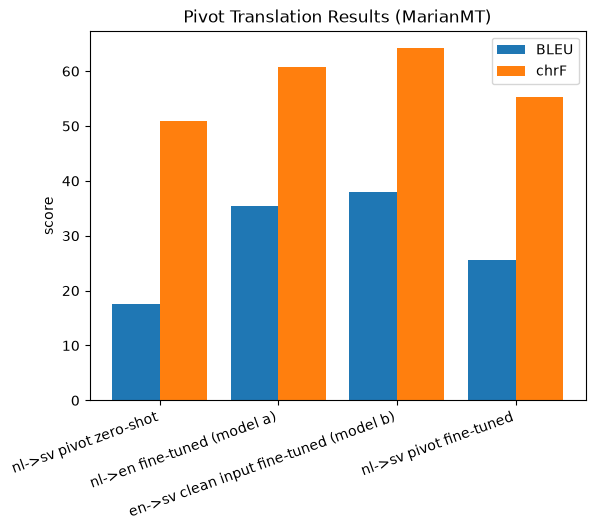

In [16]:
import matplotlib.pyplot as plt
import numpy as np

labels = list(results.keys())
bleus = [results[k][0] for k in labels]
chrfs = [results[k][1] for k in labels]

x = np.arange(len(labels))
plt.bar(x - 0.2, bleus, 0.4, label='BLEU')
plt.bar(x + 0.2, chrfs, 0.4, label='chrF')
plt.xticks(x, labels, rotation=20, ha='right')
plt.ylabel('score')
plt.title('Pivot Translation Results (MarianMT)')
plt.legend()

plt.savefig('task5_figure1', dpi=300, bbox_inches='tight')

plt.show()

In [17]:
# some example translation chains
for i in range(5):
    row = test_eval.iloc[i]
    print(f"nl:          {row['nl']}")
    print(f"en (model):  {hyp_en[i]}")
    print(f"en (ref):    {row['en']}")
    print(f"sv (pivot):  {hyp_sv_pivot[i]}")
    print(f"sv (ref):    {row['sv']}")
    print()

nl:          is het niet veeleer zo dat we voor meer bureaucratie en complexe procedures zorgen
en (model):  is it not rather that we create more bureaucracy and complex procedures
en (ref):    is it not rather the case that we are creating more bureaucracy and complicated procedures
sv (pivot):  är det inte snarare så att vi skapar mer byråkrati och komplexa förfaranden
sv (ref):    är det inte snarare så att vi ökar byråkratin och krånglet

nl:          toch zal ik afronden met twee bemoedigende constateringen
en (model):  nevertheless i will conclude with two encouraging observations
en (ref):    i would however like to conclude on two encouraging points
sv (pivot):  jag vill ändå avsluta med två uppmuntrande iakttagelser
sv (ref):    jag vill dock avsluta med två positiva punkter

nl:          de vergadering wordt om 2000 uur onderbroken en om 2105 uur hervat
en (model):  the sitting was suspended at 2000 and resumed at 2105
en (ref):    the sitting was suspended at 8 pm and resume